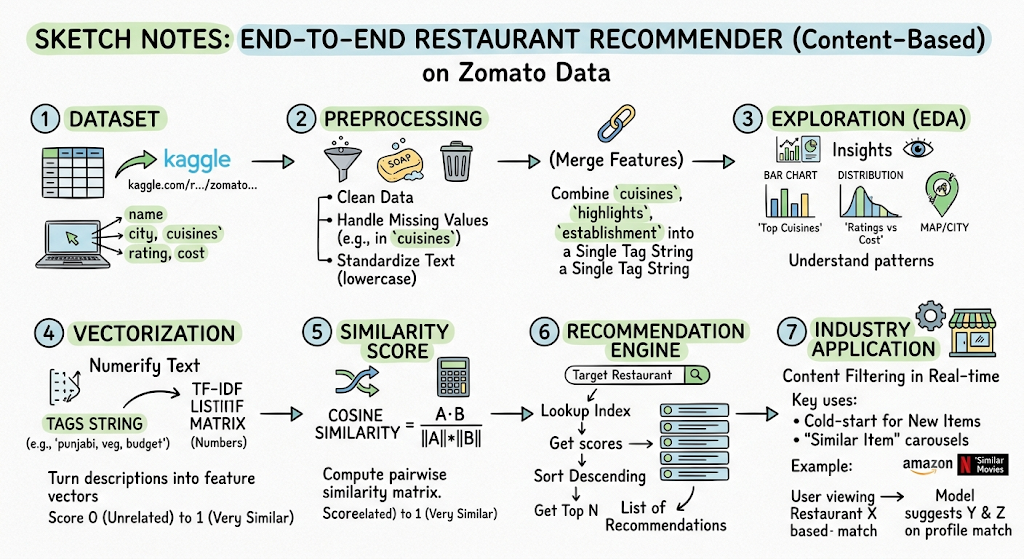

# Zomato Restaurant Recommendation System

A content-based recommendation project using Chennai restaurant data.

## Setup and Imports

In [1]:
# pip install plotly

In [276]:
# pip install scipy

In [277]:
# pip install scikit-learn

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [279]:
pd.set_option('display.max_columns', None)

## Load and Inspect the Data

**What is happening here?** We load the restaurant data, check its columns and quality, and keep restaurants in Chennai.

In [2]:
## reading the data
zom = pd.read_csv("E:\\Zomato recommendation system\\zomato_restaurants_in_India.csv")

### Basic data exploration

In [3]:
zom.shape

(211944, 26)

In [282]:
zom.columns

Index(['res_id', 'name', 'establishment', 'url', 'address', 'city', 'city_id',
       'locality', 'latitude', 'longitude', 'zipcode', 'country_id',
       'locality_verbose', 'cuisines', 'timings', 'average_cost_for_two',
       'price_range', 'currency', 'highlights', 'aggregate_rating',
       'rating_text', 'votes', 'photo_count', 'opentable_support', 'delivery',
       'takeaway'],
      dtype='str')

In [283]:
display(zom.head(2))

,res_id,name,establishment,url,address,city,city_id,locality,latitude,longitude,zipcode,country_id,locality_verbose,cuisines,timings,average_cost_for_two,price_range,currency,highlights,aggregate_rating,rating_text,votes,photo_count,opentable_support,delivery,takeaway
0,3400299,Bikanervala,['Quick Bites'],https://www.zomato.com/agra/bikanervala-khanda...,"Kalyani Point, Near Tulsi Cinema, Bypass Road,...",Agra,34,Khandari,27.211450,78.002381,NaN,1,"Khandari, Agra","North Indian, South Indian, Mithai, Street Foo...",8:30am â€“ 10:30pm (Mon-Sun),700,2,Rs.,"['Lunch', 'Takeaway Available', 'Credit Card',...",4.4,Very Good,814,154,0.0,-1,-1
1,3400005,Mama Chicken Mama Franky House,['Quick Bites'],https://www.zomato.com/agra/mama-chicken-mama-...,"Main Market, Sadar Bazaar, Agra Cantt, Agra",Agra,34,Agra Cantt,27.160569,78.011583,282001.0,1,"Agra Cantt, Agra","North Indian, Mughlai, Rolls, Chinese, Fast Fo...","12:30PM to 12Midnight (Mon, Wed, Thu, Fri, Sat...",600,2,Rs.,"['Delivery', 'No Alcohol Available', 'Dinner',...",4.4,Very Good,1203,161,0.0,-1,-1


### Filtering only Chennai location restaurants

In [284]:
ch = zom[zom['city'] == 'Chennai']

In [285]:
ch.shape

(11630, 26)

In [286]:
ch.info()

<class 'pandas.DataFrame'>
RangeIndex: 11630 entries, 33460 to 45089
Data columns (total 26 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   res_id                11630 non-null  int64  
 1   name                  11630 non-null  str    
 2   establishment         11630 non-null  str    
 3   url                   11630 non-null  str    
 4   address               11630 non-null  str    
 5   city                  11630 non-null  str    
 6   city_id               11630 non-null  int64  
 7   locality              11630 non-null  str    
 8   latitude              11630 non-null  float64
 9   longitude             11630 non-null  float64
 10  zipcode               5043 non-null   str    
 11  country_id            11630 non-null  int64  
 12  locality_verbose      11630 non-null  str    
 13  cuisines              11630 non-null  str    
 14  timings               11630 non-null  str    
 15  average_cost_for_two  1163

In [287]:
ch.describe()

,res_id,city_id,latitude,longitude,country_id,average_cost_for_two,price_range,aggregate_rating,votes,photo_count,opentable_support,delivery,takeaway
count,1.163000e+04,11630.0,11630.000000,11630.000000,11630.0,11630.000000,11630.000000,11630.000000,11630.000000,11630.000000,11630.0,11630.000000,11630.0
mean,1.016282e+07,7.0,12.998636,80.185039,1.0,898.277730,2.123474,3.973938,719.630095,450.583663,0.0,-0.227945,-1.0
std,9.274464e+06,0.0,0.191378,1.488801,0.0,734.606969,0.979307,0.609183,1067.202562,693.106541,0.0,0.972346,0.0
min,6.501100e+04,7.0,0.000000,0.000000,1.0,40.000000,1.000000,0.000000,0.000000,0.000000,0.0,-1.000000,-1.0
25%,7.002300e+04,7.0,12.971963,80.211756,1.0,400.000000,1.000000,3.800000,135.000000,37.000000,0.0,-1.000000,-1.0
50%,1.840350e+07,7.0,13.038089,80.232507,1.0,700.000000,2.000000,4.000000,424.000000,187.000000,0.0,-1.000000,-1.0
75%,1.866420e+07,7.0,13.056209,80.249614,1.0,1300.000000,3.000000,4.300000,929.000000,541.000000,0.0,1.000000,-1.0
max,1.915445e+07,7.0,13.163015,80.293703,1.0,5500.000000,4.000000,4.900000,10171.000000,5787.000000,0.0,1.000000,-1.0


In [288]:
ch.isnull().sum()

res_id                     0
name                       0
establishment              0
url                        0
address                    0
city                       0
city_id                    0
locality                   0
latitude                   0
longitude                  0
zipcode                 6587
country_id                 0
locality_verbose           0
cuisines                   0
timings                    0
average_cost_for_two       0
price_range                0
currency                   0
highlights                 0
aggregate_rating           0
rating_text                0
votes                      0
photo_count                0
opentable_support          0
delivery                   0
takeaway                   0
dtype: int64

In [289]:
ch.columns

Index(['res_id', 'name', 'establishment', 'url', 'address', 'city', 'city_id',
       'locality', 'latitude', 'longitude', 'zipcode', 'country_id',
       'locality_verbose', 'cuisines', 'timings', 'average_cost_for_two',
       'price_range', 'currency', 'highlights', 'aggregate_rating',
       'rating_text', 'votes', 'photo_count', 'opentable_support', 'delivery',
       'takeaway'],
      dtype='str')

**Summary:** We loaded and checked the data, then selected the restaurants in Chennai.

### Select and Clean Restaurant Data

**What is happening here?** We keep the columns needed for this project, check the data, and remove duplicate rows.

In [290]:
##selecting the required columns for analysis
ch_sel = ch[['name','city','locality','establishment','cuisines','average_cost_for_two','price_range','aggregate_rating','rating_text','votes']]

In [291]:
display(ch_sel.head(2))

,name,city,locality,establishment,cuisines,average_cost_for_two,price_range,aggregate_rating,rating_text,votes
33460,The Black Pearl,Chennai,Sholinganallur,['Casual Dining'],"North Indian, European, Mediterranean, Contine...",1500,3,4.8,Excellent,2486
33461,Fromage,Chennai,MRC Nagar,['CafÃ©'],"Cafe, Italian, French, European",1000,3,4.5,Excellent,1053


In [292]:
# 1. Split comma-separated strings into lists, strip extra spaces, and explode
individual_cuisines = (
ch_sel['cuisines'].dropna()
.str.split(',')
.explode()
.str.strip()
)

# 2. Get the true frequency of each individual cuisine
cuisine_counts = individual_cuisines.value_counts()

print("Total unique individual cuisines:", len(cuisine_counts))
print(cuisine_counts.head(30))

Total unique individual cuisines: 85
cuisines
North Indian    4647
Chinese         2731
Continental     2528
South Indian    2115
Fast Food       1780
Biryani         1712
Italian         1599
Beverages       1575
Cafe            1413
Desserts        1371
Finger Food      732
BBQ              637
Burger           579
American         568
Asian            562
Seafood          462
Ice Cream        437
Pizza            401
Juices           387
Mexican          382
Bakery           382
Chettinad        374
European         352
Arabian          346
Bar Food         344
Thai             304
Kerala           301
Street Food      299
Salad            287
Andhra           285
Name: count, dtype: int64


In [293]:
## data validation for duplicate rows
duplicate_rows = ch_sel[ch_sel.duplicated()]

In [294]:
duplicate_rows.shape

(9757, 10)

In [295]:
# display(ch[(ch['name']=="Coal Barbecues") & (ch['locality']=="T. Nagar")])

In [296]:
# ch_sel[ch_sel['name']=="Coal Barbecues"]

In [297]:
## drop duplicate rows
ch_sel = ch_sel.drop_duplicates()

In [298]:
ch_sel.shape

(1873, 10)

**Summary:** We kept useful columns and removed duplicate rows. Missing values were checked, but not all were removed.

## Explore Chennai Restaurants

**What is happening here?** We use charts and simple counts to learn about the restaurants in the dataset.

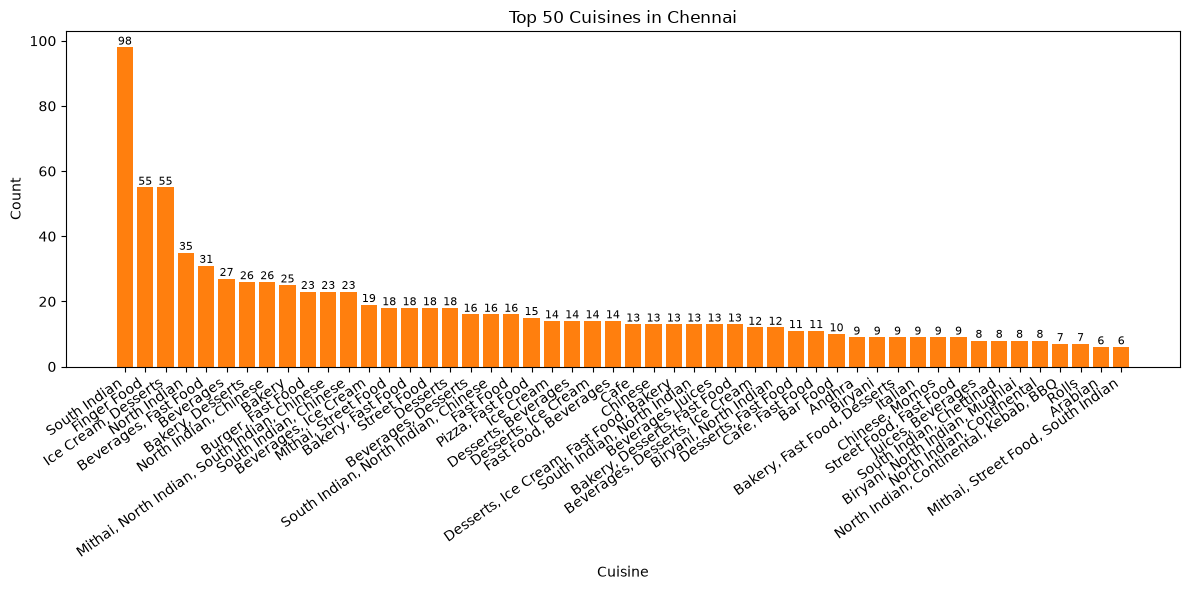

In [299]:
##visualize restaurant cuisines in Chennai
cuisine_counts = ch_sel.groupby(ch_sel['cuisines']).size().sort_values(ascending=False)
plt.figure(figsize=(12, 6))
plt.bar(cuisine_counts.index[:50], cuisine_counts.values[:50])
plt.bar_label(plt.bar(cuisine_counts.index[:50], cuisine_counts.values[:50]), label_type='edge', fontsize=8)
plt.xlabel('Cuisine')
plt.ylabel('Count')
plt.title('Top 50 Cuisines in Chennai')
plt.xticks(rotation=35, ha='right')
plt.tight_layout()
plt.show()


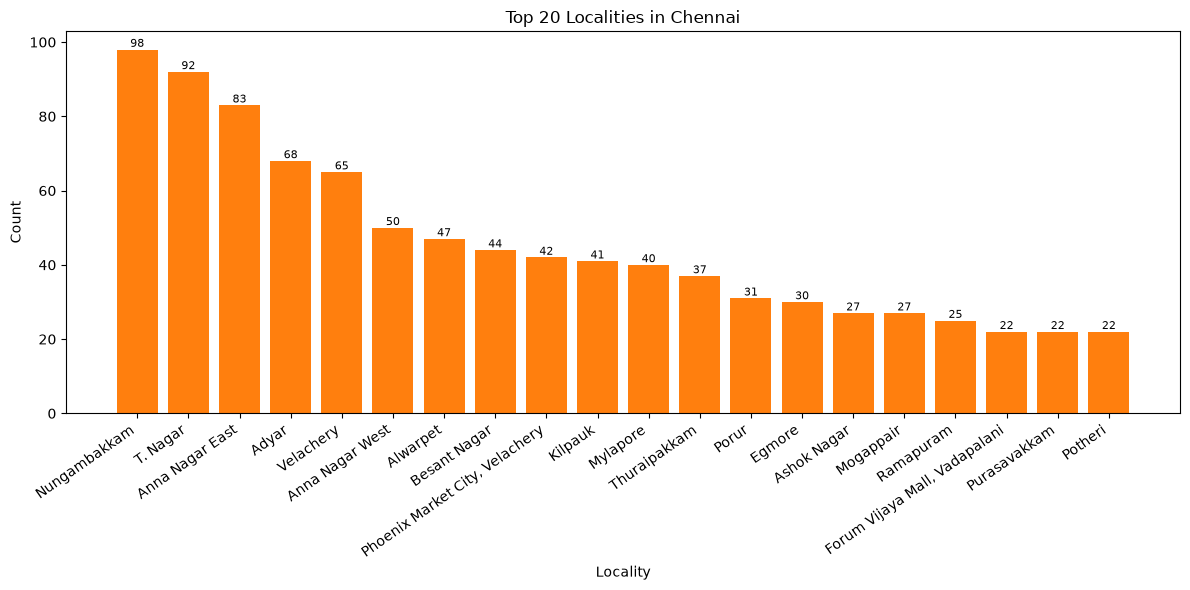

In [300]:
#visualize top locations in Chennai
location_counts = ch_sel['locality'].value_counts().head(20)    
plt.figure(figsize=(12, 6))
plt.bar(location_counts.index, location_counts.values)
plt.bar_label(plt.bar(location_counts.index, location_counts.values), label_type='edge', fontsize=8)
plt.xlabel('Locality')
plt.ylabel('Count')
plt.title('Top 20 Localities in Chennai')   
plt.xticks(rotation=35, ha='right')
plt.tight_layout()
plt.show()

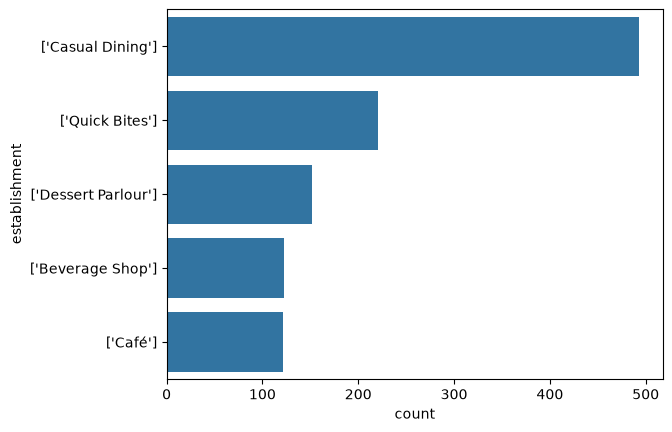

In [301]:
#top 5 establishment types in Chennai in sns plots
plot = sns.countplot(data=ch_sel, y='establishment', order=ch_sel['establishment'].value_counts().index[:5])

In [302]:
## the values in the establishment column has [] in the value hence removing it using extract function use regex 
ch_sel['establishment'] = ch_sel['establishment'].str.extract(r"\['(.*?)'\]")

#`r"\['(.*?)'\]"` matches literal `['` and `']`, capturing and extracting everything inside the inner single quotes `(.*?)`.

In [303]:
ch_sel['establishment'].head(2)

33460    Casual Dining
33461             CafÃ©
Name: establishment, dtype: str

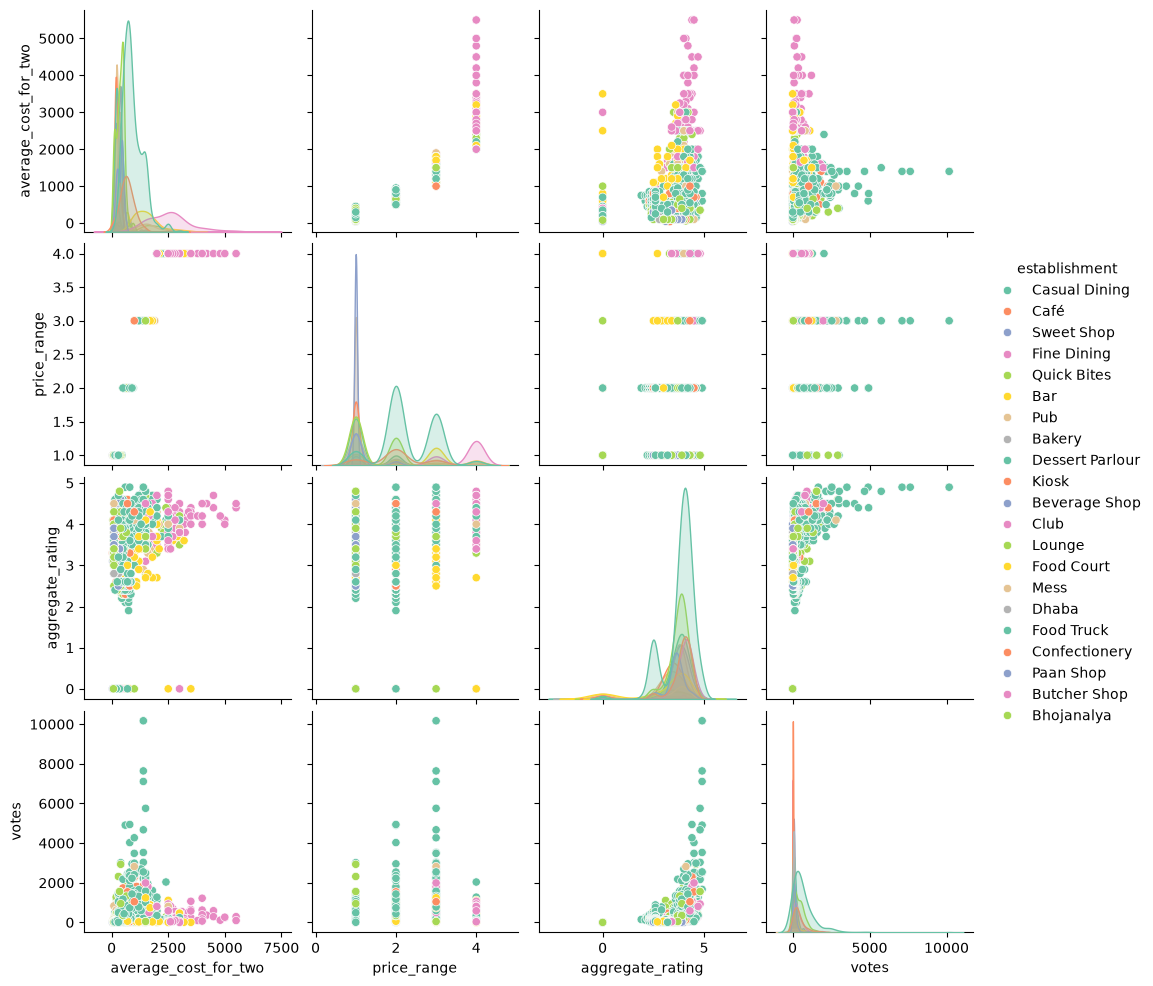

In [304]:
## restaurant price range distribution in Chennai using pairplot
sns.pairplot(ch_sel, vars=['average_cost_for_two', 'price_range', 'aggregate_rating', 'votes'], hue='establishment', palette='Set2')

In [305]:
## finding the correlation between the variables
num_val = ch_sel.select_dtypes(include=[np.number])
num_val.corr()

,average_cost_for_two,price_range,aggregate_rating,votes
average_cost_for_two,1.000000,0.893296,0.236004,0.169218
price_range,0.893296,1.000000,0.264863,0.250112
aggregate_rating,0.236004,0.264863,1.000000,0.331006
votes,0.169218,0.250112,0.331006,1.000000


In [307]:
import plotly.express as px
top10_df = ch_sel[['name','votes']].drop_duplicates()
# Select top 10 restaurants by votes
top10_df = top10_df.nlargest(10, "votes")

fig = px.bar(
    top10_df,
    x="name",
    y="votes",
    color="name",  # Adds restaurant names as legends
    title="Top 10 Restaurants by Total Votes",
    labels={"votes": "Total Votes", "name": "Restaurant Name"},

)

fig.update_layout(
    template="plotly_white",
    xaxis_title="Restaurant Name",
    yaxis_title="Total Votes",
    xaxis={
        "categoryorder": "total descending"
    },  # Sorts bars from highest to lowest
)

fig.show()

In [308]:
# plt.figure(figsize=(8, 6))
# sns.heatmap(num_val, annot=True, cmap='Spectral') #Spectral
# plt.title('Variable Correlation Heatmap')
# plt.show()

**Summary:** The charts show common cuisines, locations, and restaurant types in Chennai.

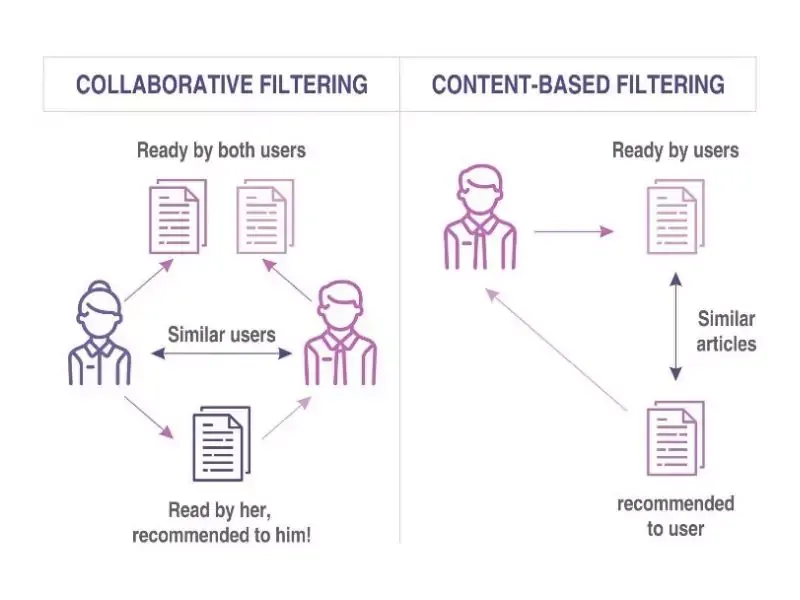

## Select Recommendation Features

**What is happening here?** We choose and prepare restaurant details that the system can use to compare restaurants.

### Weighted Rating

Weighted Rating (often called the Bayesian Average) solves a fundamental flaw in raw averages: a restaurant with a single 5-star rating (1 vote) appears "better" than a restaurant with a 4.8 rating across 2,500 votes.

If you rank restaurants purely by aggregate_rating, low-traffic venues with very few reviews pollute the top recommendations. Weighted Rating balances quality (aggregate_rating) with confidence (votes).

Weighted Rating pulls a restaurant's score toward the dataset average ($C$) until the restaurant gathers enough votes to prove its true quality.The standard formula (used by IMDb and recommendation systems):$$\text{Weighted Rating } (WR) = \left(\frac{v}{v + m} \times R\right) + \left(\frac{m}{v + m} \times C\right)$$

$R$ = Restaurant's actual rating (e.g., 4.8)$v$ = Restaurant's total votes (e.g., 2486)$C$ = Dataset average rating across all restaurants (e.g., 3.8)$m$ = Minimum votes threshold required to be considered reliable (e.g., top 25th percentile of votes, say 100 votes)

In [309]:
# Calculate mean rating across dataset (C) and minimum vote threshold (m)
v = ch_sel["votes"]
R = ch_sel["aggregate_rating"]
C = R.mean()
m = v.quantile(0.50)  # Use 50th percentile threshold for small sample

ch_sel["weighted_rating"] = (v / (v + m) * R) + (m / (v + m) * C)
ch_sel[["name", "aggregate_rating", "votes", "weighted_rating"]].head(2)

,name,aggregate_rating,votes,weighted_rating
33460,The Black Pearl,4.8,2486,4.732736
33461,Fromage,4.5,1053,4.389733


### Combine Restaurant Features

In [310]:
# Clean missing values
# Combine Establishment + Cuisines (Boost establishment weight by duplicating it)
ch_sel["combined_features"] = (
    ch_sel["establishment"] + ", " + ch_sel["establishment"] + ", " + ch_sel["cuisines"]
)

ch_sel[["name", "combined_features"]]

,name,combined_features
33460,The Black Pearl,"Casual Dining, Casual Dining, North Indian, Eu..."
33461,Fromage,"CafÃ©, CafÃ©, Cafe, Italian, French, European"
33462,Coal Barbecues,"Casual Dining, Casual Dining, North Indian, Me..."
33463,Coal Barbecues,"Casual Dining, Casual Dining, North Indian, Me..."
33464,The Bark,"CafÃ©, CafÃ©, Cafe, Mexican, Italian, Continental"
...,...,...
44342,Blu Hickey Bistro - Radisson Blu GRT Hotel,"Fine Dining, Fine Dining, North Indian, South ..."
44350,The Slice - Radisson Blu GRT Hotel,"Dessert Parlour, Dessert Parlour, Desserts, Ba..."
44485,Up North - The Raintree,"Fine Dining, Fine Dining, North Indian"
44721,Mathsya,"Casual Dining, Casual Dining, South Indian, No..."


When using bag-of-words vectorizers (CountVectorizer or TF-IDF), duplicating a term changes its weight in the similarity formula.

Why Duplicate the Term?
By default, CountVectorizer counts how many times a word appears in a string.

If your string is:
"Casual Dining, North Indian, European, Mediterranean, Continental"

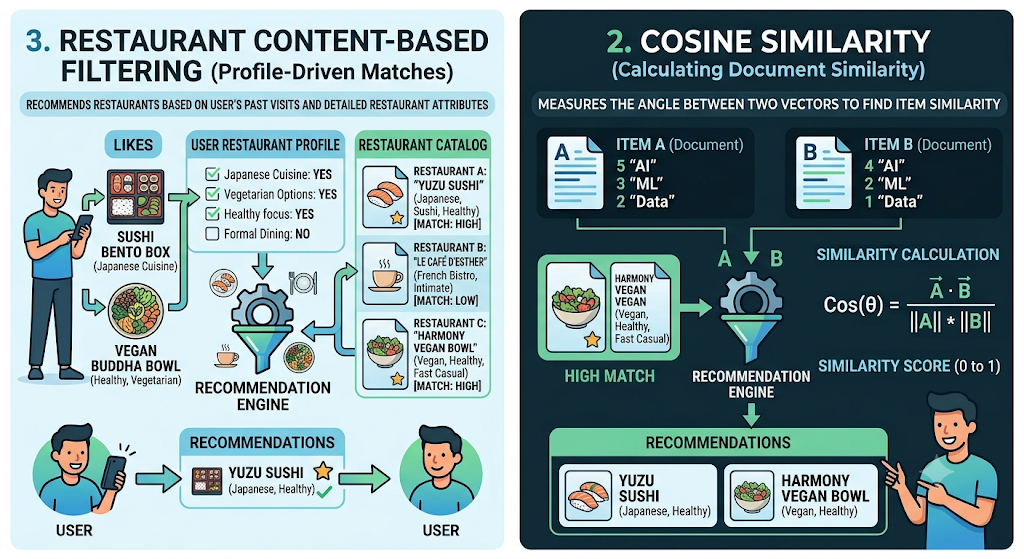

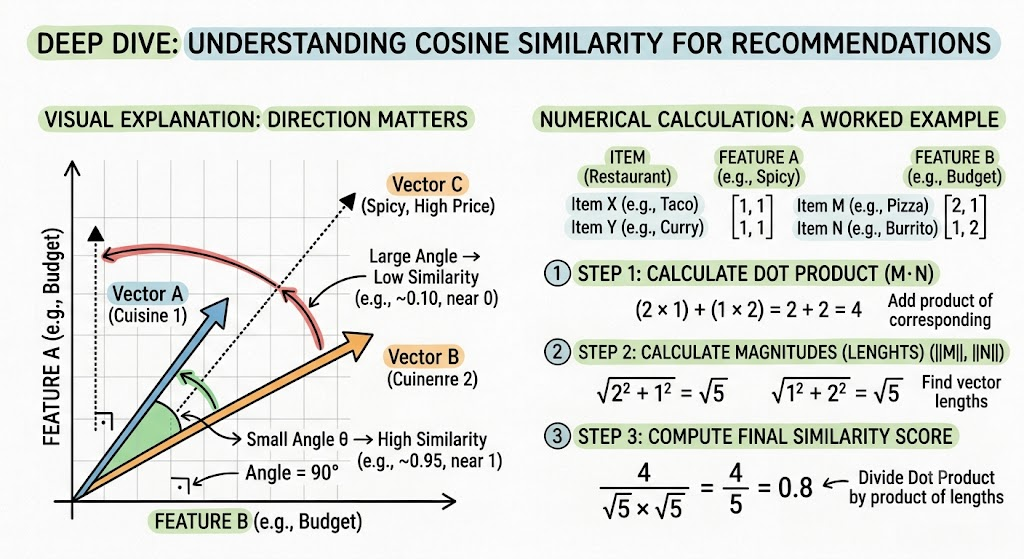

**Content-Based Filtering** recommends items by matching their traits (like a restaurant's cuisine or price) to what you've liked in the past.

**Cosine Similarity** is the math tool that calculates this match by measuring how closely two sets of traits point in the same direction, giving a similarity score between 0 and 1. Together, they help apps suggest new options that fit your personal taste.

**Summary:** We prepared restaurant features and a balanced rating for comparing restaurants.

## Build and Use Recommendations

**What is happening here?** We compare restaurants using the chosen features and return places similar to the selected restaurant.

In [311]:
import sklearn

In [312]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics.pairwise import cosine_similarity

In [313]:
ch_sel.columns

Index(['name', 'city', 'locality', 'establishment', 'cuisines',
       'average_cost_for_two', 'price_range', 'aggregate_rating',
       'rating_text', 'votes', 'weighted_rating', 'combined_features'],
      dtype='str')

In [314]:
# Custom tokenizer splits by comma and strips extra spaces
def clean_tokenizer(x):
    return [item.strip().lower() for item in x.split(",") if item.strip()]
# Fit vectorizer
vectorizer = CountVectorizer(tokenizer=clean_tokenizer)
ch_sel['combined_features'] = ch_sel['combined_features'].fillna('')

ch_sel = ch_sel.reset_index(drop=True)

feature_bow = vectorizer.fit_transform(ch_sel["combined_features"])

# Compute NxN Cosine Similarity Matrix
cosine_sim_matrix = cosine_similarity(feature_bow, feature_bow)

print("Feature Matrix Shape:", feature_bow.shape)
print("Cosine Similarity Matrix Shape:", cosine_sim_matrix.shape)

Feature Matrix Shape: (1873, 105)
Cosine Similarity Matrix Shape: (1873, 1873)


C:\Users\Acer\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\feature_extraction\text.py:527: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(


In [315]:
# --- VISUALIZING THE SIMILARITY MATRIX ---

# Convert matrix to DataFrame with restaurant names as headers for easy reading
sim_matrix_df = pd.DataFrame(
    cosine_sim_matrix, index=ch_sel["name"], columns=ch_sel["name"]
)

print("=== 1. ORIGINAL DATASET ===")
display(ch_sel[["name", "establishment", "cuisines"]])

print("\n=== 2. COSINE SIMILARITY MATRIX ===")
# Formatted to 2 decimal places for clarity
display(sim_matrix_df.round(2))

=== 1. ORIGINAL DATASET ===


,name,establishment,cuisines
0,The Black Pearl,Casual Dining,"North Indian, European, Mediterranean, Contine..."
1,Fromage,CafÃ©,"Cafe, Italian, French, European"
2,Coal Barbecues,Casual Dining,"North Indian, Mediterranean, Asian, Arabian, BBQ"
3,Coal Barbecues,Casual Dining,"North Indian, Mediterranean, Asian, Arabian, BBQ"
4,The Bark,CafÃ©,"Cafe, Mexican, Italian, Continental"
...,...,...,...
1868,Blu Hickey Bistro - Radisson Blu GRT Hotel,Fine Dining,"North Indian, South Indian, Chinese, Asian, Me..."
1869,The Slice - Radisson Blu GRT Hotel,Dessert Parlour,"Desserts, Bakery"
1870,Up North - The Raintree,Fine Dining,North Indian
1871,Mathsya,Casual Dining,"South Indian, North Indian, Chinese, Beverages"



=== 2. COSINE SIMILARITY MATRIX ===


name                                        The Black Pearl  Fromage  \
name                                                                   
The Black Pearl                                        1.00     0.12   
Fromage                                                0.12     1.00   
Coal Barbecues                                         0.78     0.00   
Coal Barbecues                                         0.78     0.00   
The Bark                                               0.12     0.75   
...                                                     ...      ...   
Blu Hickey Bistro - Radisson Blu GRT Hotel             0.10     0.00   
The Slice - Radisson Blu GRT Hotel                     0.00     0.00   
Up North - The Raintree                                0.15     0.00   
Mathsya                                                0.59     0.00   
Chamiers Cafe                                          0.11     0.71   

name                                        Coal Barbecues  Coal Barbecues  \
name                                                                         
The Black Pearl                                       0.78            0.78   
Fromage                                               0.00            0.00   
Coal Barbecues                                        1.00            1.00   
Coal Barbecues                                        1.00            1.00   
The Bark                                              0.00            0.00   
...                                                    ...             ...   
Blu Hickey Bistro - Radisson Blu GRT Hotel            0.20            0.20   
The Slice - Radisson Blu GRT Hotel                    0.00            0.00   
Up North - The Raintree                               0.15            0.15   
Mathsya                                               0.59            0.59   
Chamiers Cafe                                         0.00            0.00   

name                                        The Bark  Dhaba Estd 1986 Delhi  \
name                                                                          
The Black Pearl                                 0.12                   0.75   
Fromage                                         0.75                   0.00   
Coal Barbecues                                  0.00                   0.75   
Coal Barbecues                                  0.00                   0.75   
The Bark                                        1.00                   0.00   
...                                              ...                    ...   
Blu Hickey Bistro - Radisson Blu GRT Hotel      0.11                   0.13   
The Slice - Radisson Blu GRT Hotel              0.00                   0.00   
Up North - The Raintree                         0.00                   0.20   
Mathsya                                         0.00                   0.79   
Chamiers Cafe                                   0.82                   0.00   

name                                        Coal Barbecues  Nasi And Mee  \
name                                                                       
The Black Pearl                                       0.78          0.42   
Fromage                                               0.00          0.00   
Coal Barbecues                                        1.00          0.53   
Coal Barbecues                                        1.00          0.53   
The Bark                                              0.00          0.00   
...                                                    ...           ...   
Blu Hickey Bistro - Radisson Blu GRT Hotel            0.20          0.19   
The Slice - Radisson Blu GRT Hotel                    0.00          0.00   
Up North - The Raintree                               0.15          0.00   
Mathsya                                               0.59          0.56   
Chamiers Cafe                                         0.00          0.00   

name                           

In [316]:
# --- HOW THE LOOKUP WORKS IN ACTION ---
target_name = "The Roof Top Lounge"

# Step A: Find row index
target_pos = ch_sel[ch_sel["name"].str.lower() == target_name.lower()].index[0]

print(f"\n=== 3. LOOKUP STEP FOR '{target_name}' ===")
display(f"Target Row Index: {target_pos}")

# Step B: Extract similarity vector for target row
sim_scores = cosine_sim_matrix[target_pos]

# Step C: Attach scores back to DataFrame
demo_ch_sel = ch_sel[["name", "cuisines"]].copy()
demo_ch_sel["similarity_score"] = np.round(sim_scores, 2)

print("\n=== 4. SCORES ATTACHED BACK TO RESTAURANTS ===")
display(demo_ch_sel.sort_values(by="similarity_score", ascending=False))


=== 3. LOOKUP STEP FOR 'The Roof Top Lounge' ===


'Target Row Index: 1047'


=== 4. SCORES ATTACHED BACK TO RESTAURANTS ===


,name,cuisines,similarity_score
1047,The Roof Top Lounge,"BBQ, North Indian, Continental",1.00
1252,Barbeque Nation,"North Indian, Continental, Kebab, BBQ",0.94
89,Barbeque Nation,"North Indian, Continental, Kebab, BBQ",0.94
1254,Barbeque Nation,"North Indian, Continental, Kebab, BBQ",0.94
1257,Barbeque Nation,"North Indian, Continental, Kebab, BBQ",0.94
...,...,...,...
48,Fusilli Reasons,Italian,0.00
78,Eatza Pizza,"Pizza, Fast Food",0.00
1854,McDonald's,"Burger, Fast Food",0.00
1850,Chennight Restaurant,"Chinese, South Indian",0.00


Here is a crisp, point-by-point breakdown of what the code does:

* **Core Purpose:** Recommends restaurants based on a **target restaurant name** (using similarity), a **locality** (location), or both.
* **Case 1 (Restaurant Search):** Looks up the target restaurant, retrieves its similarity scores across all items from `cosine_sim`, and removes the original target from the output list.
* **Case 2 (Locality-Only Search):** If no restaurant name is provided, sets similarity scores to `NaN` and prepares to recommend based purely on popularity and rating.
* **Case 3 (No Input):** Returns an error if neither a restaurant name nor a locality is provided.
* **Locality Filtering:** Filters the dataset down to the specified location (if provided), converting text to lowercase to prevent casing mismatches.
* **Smart Sorting:**
* If a **target restaurant** is given: Sorts primarily by **similarity score**, followed by **weighted rating** and **votes**.
* If **locality only**: Sorts purely by quality (**weighted rating**) and popularity (**votes**).


* **Deduplication & Output:** Removes duplicate restaurant names (keeping the highest-ranked entry) and returns the top $N$ results with key details like name, locality, cuisines, rating, and similarity score.

In [343]:
import numpy as np
import pandas as pd


def recommend_restaurants(
    df,
    target_restaurant_name=None,  # Optional
    locality=None,  # Optional
    top_n=5,
    cosine_sim=cosine_sim_matrix,
):
    df_reset = df.reset_index(drop=True)

    # -------------------------------------------------------------
    # CASE 1: USER PROVIDED A TARGET RESTAURANT (Similarity Search)
    # -------------------------------------------------------------
    if target_restaurant_name:
        matches = np.where(
            df_reset["name"].str.lower() == target_restaurant_name.lower()
        )[0]

        if len(matches) == 0:
            print(f"Error: '{target_restaurant_name}' not found in dataset.")
            return pd.DataFrame()

        target_pos = matches[0]
        results_df = df_reset.copy()
        results_df["similarity_score"] = cosine_sim[target_pos]

        # Exclude exact target restaurant match from the recommendations
        results_df = results_df[
            results_df["name"].str.lower() != target_restaurant_name.lower()
        ]

    # -------------------------------------------------------------
    # CASE 2: USER PROVIDED ONLY A LOCALITY (Popularity / Rating Search)
    # -------------------------------------------------------------
    elif locality:
        results_df = df_reset.copy()
        results_df["similarity_score"] = np.nan

    # -------------------------------------------------------------
    # CASE 3: NO INPUT PROVIDED
    # -------------------------------------------------------------
    else:
        print(
            "Error: Please provide either a 'target_restaurant_name' or a 'locality'."
        )
        return pd.DataFrame()

    # STEP 2: Filter by Locality (applies whether name was given or not)
    if locality:
        results_df = results_df[
            results_df["locality"].str.lower() == locality.lower()
        ]

    if results_df.empty:
        print("No restaurants found matching the specified locality criteria.")
        return pd.DataFrame()

    # STEP 3: Sort logic
    if target_restaurant_name:
        # Sort by similarity first, then quality
        sort_cols = ["similarity_score", "weighted_rating", "votes"]
        ascending_order = [False, False, False]
    else:
        # Sort purely by quality and popularity
        sort_cols = ["weighted_rating", "votes"]
        ascending_order = [False, False]

    recommended = results_df.sort_values(
        by=sort_cols, ascending=ascending_order
    )

    # STEP 4: Deduplicate restaurant names
    recommended["name_lower"] = recommended["name"].str.lower()
    recommended = recommended.drop_duplicates(
        subset=["name_lower"], keep="first"
    )

    # Output column formatting
    output_cols = [
        "name",
        "locality",
        "establishment",
        "cuisines",
        "weighted_rating",
        "votes",
        "similarity_score",
    ]

    return recommended[output_cols].head(top_n)

### Generate Recommendations

**What is happening here?** We use the function with a chosen restaurant to get similar places.

In [345]:

# Call recommendation function
recommend_restaurants(
    df=ch_sel,
    target_restaurant_name="The Black Pearl",
    top_n=5,
    cosine_sim=cosine_sim_matrix,
)

,name,locality,establishment,cuisines,weighted_rating,votes,similarity_score
1047,The Roof Top Lounge,"Ramada Plaza, Guindy",Casual Dining,"BBQ, North Indian, Continental",3.714048,83,0.881917
37,AB's - Absolute Barbecues,T. Nagar,Casual Dining,"BBQ, North Indian, European, Beverages",4.881382,10171,0.824958
89,Barbeque Nation,T. Nagar,Casual Dining,"North Indian, Continental, Kebab, BBQ",4.769985,5756,0.824958
49,East Coast at Madras Square,Neelangarai,Casual Dining,"European, Continental, Italian, North Indian",4.398514,1157,0.824958
1474,Food Nirvana,RA Puram,Casual Dining,"Continental, North Indian",4.144096,510,0.816497


**Summary:** The system compares restaurants and returns places similar to the selected restaurant.

## Feature Evaluation

**What is happening here?** We use statistical tests and charts to check whether numeric details help distinguish restaurant groups.

### Evaluating Numerical-Categorical Feature for Cosine Similarity

### Why Do It?

* **Prevents Vector Distortion:** Stops raw numbers (like huge vote counts) from overriding core text features like cuisine.
* **Filters Out Noise:** Identifies and drops numerical metrics that fail to differentiate one restaurant type from another.
* **Improves Accuracy:** Ensures only features with real discriminative value enter the cosine similarity matrix.

---

### Why Use ANOVA?

* **Connects Text to Numbers:** Standard correlation ($r$) only compares numbers to numbers; ANOVA tests numbers across distinct category groups.
* **Compares Group Variance:** Checks if variations in metrics (like `cost` or `rating`) are driven by establishment types rather than random chance.
* **Handles Skewed Data:** Uses non-parametric alternatives (Kruskal-Wallis) to safely analyze non-normal metrics like `votes`.

---

### The Decision Rule ($p$-value)

* **$p < 0.05$ (Significant Signal):** The numerical metric varies meaningfully across categories $\rightarrow$ **Keep, scale, and append** to text vectors.
* **$p \ge 0.05$ (Random Noise):** The numerical metric shows no real pattern across categories $\rightarrow$ **Drop it** to keep recommendations accurate.

In [328]:
from scipy import stats


def test_category_numerical_relationship(df, cat_col, num_col):
    # Split the numerical feature into groups based on category values
    groups = [
        group[num_col].dropna().values
        for _, group in df.groupby(cat_col)
        if len(group) > 1
    ]

    if len(groups) < 2:
        print(f"Skipping {cat_col} vs {num_col}: Not enough valid groups.\n")
        return

    # WHY ANOVA: Checks if average numbers (like cost) differ across category groups.
    f_stat, p_val_anova = stats.f_oneway(*groups)

    # WHY KRUSKAL-WALLIS: Safer alternative for heavily skewed data (like votes/ratings) that doesn't follow a normal bell curve.
    h_stat, p_val_kruskal = stats.kruskal(*groups)

    print(f"--- Analysis: [{cat_col}] vs [{num_col}] ---")
    print(f"  â€¢ ANOVA p-value: {p_val_anova:.4f}")
    print(f"  â€¢ Kruskal-Wallis p-value: {p_val_kruskal:.4f}")

    # Decision based on Kruskal-Wallis result
    if p_val_kruskal < 0.05:
        print(
            f"  âœ… KEEP [{num_col}]: Significantly varies across [{cat_col}] (p = {p_val_kruskal:.4f})"
        )
        print("     -> Good feature! Adds strong predictive value.\n")
    else:
        print(
            f"  âŒ DROP [{num_col}]: No significant difference across [{cat_col}] (p = {p_val_kruskal:.4f})"
        )
        print("     -> Skip feature! Mostly adds random noise.\n")

In [329]:
 #RUNNING STATISTICAL TESTS
# Evaluate specific feature pairs for significance
# =====================================================================
test_category_numerical_relationship(ch_sel, "establishment", "average_cost_for_two")
test_category_numerical_relationship(ch_sel, "establishment", "weighted_rating")
test_category_numerical_relationship(ch_sel, "combined_features", "votes")

--- Analysis: [establishment] vs [average_cost_for_two] ---
  â€¢ ANOVA p-value: 0.0000
  â€¢ Kruskal-Wallis p-value: 0.0000
  âœ… KEEP [average_cost_for_two]: Significantly varies across [establishment] (p = 0.0000)
     -> Good feature! Adds strong predictive value.

--- Analysis: [establishment] vs [weighted_rating] ---
  â€¢ ANOVA p-value: 0.0000
  â€¢ Kruskal-Wallis p-value: 0.0000
  âœ… KEEP [weighted_rating]: Significantly varies across [establishment] (p = 0.0000)
     -> Good feature! Adds strong predictive value.

--- Analysis: [combined_features] vs [votes] ---
  â€¢ ANOVA p-value: 0.0000
  â€¢ Kruskal-Wallis p-value: 0.0000
  âœ… KEEP [votes]: Significantly varies across [combined_features] (p = 0.0000)
     -> Good feature! Adds strong predictive value.



C:\Users\Acer\AppData\Local\Temp\ipykernel_14968\2584116136.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


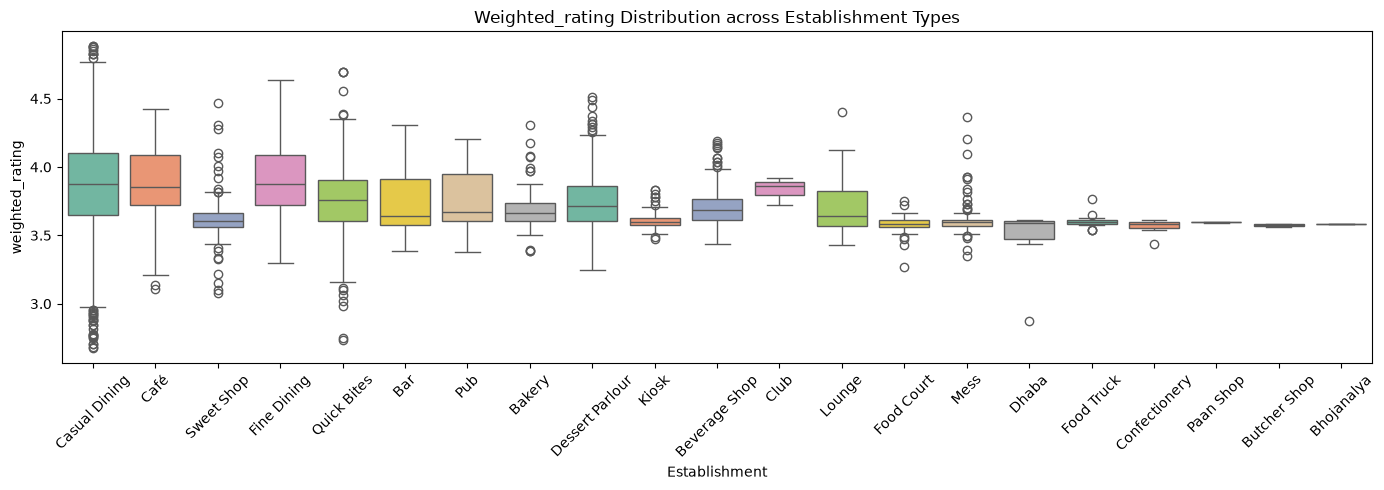

In [339]:
# =====================================================================
# CELL 4: DATA VISUALIZATION
# Plot distributions to visually inspect category separation
# =====================================================================
fig, axes = plt.subplots(1, 1, figsize=(14, 5))

# Plot 1: Boxplot for Cost vs Establishment
sns.boxplot(
    data=ch_sel,
    x="establishment",
    y="weighted_rating",
    palette="Set2"
)
axes.set_title("Weighted_rating Distribution across Establishment Types")
axes.set_xlabel("Establishment")
axes.set_ylabel("weighted_rating")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Summary:** The tests and charts help us judge whether numeric features are useful for comparing restaurant groups.